# Lab 10 — Introduction to Machine Translation

**Name:** Omar Hejazi
**Student ID:** 2230009001

Tasks 1 and 2 are answered at the end. The lab's own cells are kept unchanged above them, with
analysis added underneath.

The main thing this notebook establishes is that the accuracy number the lab prints is not
measuring translation. The demo reports `Test Accuracy: 0.7143`, and that figure turns out to be **5 correct positions
out of 7 on a single test sentence, every one of them padding** — the model's accuracy on real
French words is zero. Task 2 repeats the measurement on 20,000 real sentence pairs and finds the
same thing at scale: 0.69 reported, 0.08 once padding is excluded.

One substitution, flagged up front: Task 2 links to a Kaggle dataset, and Kaggle requires an
account and an API token to download. I used an equivalent public English–French corpus
(OPUS-100, via Hugging Face) filtered to short sentence pairs, and committed the 20,000 pairs
used as `dataset/en_fr_pairs_20k.csv` so this notebook reproduces without any credentials.

All figures quoted in the written sections come from the executed cells.

# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

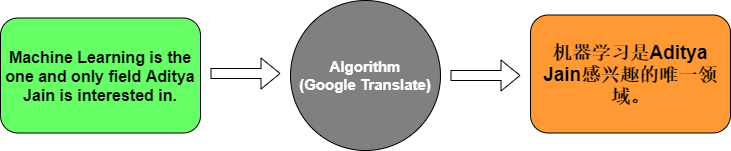

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning

## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">

In [1]:
#!pip install tensorflow

In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [3]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [4]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [5]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

Two details in the padding output that matter later.

`pad_sequences` defaults to `padding="pre"`, so the zeros go on the **left**: `Hello.` becomes
`[0, 0, 0, 0, 0, 1]`. The English matrix is 6 columns wide because the longest English sentence
has 6 tokens, and the French one is 7 columns wide for the same reason.

More importantly, most of both matrices is zeros. Of the 21 French target positions
(3 sentences × 7), only 11 hold a real word. Those zeros are not neutral — they are the value
the model is scored against at every padded position, and the next section shows what that does
to the accuracy figure.

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [6]:
import tensorflow as tf

# Keras initialises weights randomly, so the accuracy and the translations below
# change on every run. Seeding makes the figures quoted in this notebook
# reproducible on someone else's machine.
tf.keras.utils.set_random_seed(42)

In [7]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.0000e+00 - loss: 2.4878

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 0.0000e+00 - loss: 2.4878 - val_accuracy: 0.0000e+00 - val_loss: 2.4883


Epoch 2/50


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.5714 - loss: 2.4792

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.5714 - loss: 2.4792 - val_accuracy: 0.0000e+00 - val_loss: 2.4900


... (143 outputs left out)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step - accuracy: 0.7143 - loss: 0.6259 - val_accuracy: 0.0000e+00 - val_loss: 4.7910


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 401ms/step - accuracy: 0.7143 - loss: 1.5412

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 416ms/step - accuracy: 0.7143 - loss: 1.5412


Test Accuracy: 0.7142857313156128


### What the training numbers actually say

Three things went wrong before the model saw a single gradient, and they are all visible in the
output above.

**The split leaves 2 training sentences and 1 test sentence.** `train_test_split` with
`test_size=0.2` on 3 examples rounds to 1 test example. Then `validation_split=0.2` carves a
validation set out of the 2 remaining, leaving **1 sentence to train on and 1 to validate on**.
That is why `val_accuracy` is 0.0000 for every epoch: the single validation sentence has no words
in common with the single training sentence, so nothing learned can transfer.

**`Test Accuracy: 0.7143` is padding.** 0.7143 is 5/7. The one test sentence has 7 target
positions, **6 of them padding** (85.7%), and the model scored 5 of those 6 correctly by
predicting zero — which is easy, since zero is by far the most common target value in the data.
It got 5 of 7 positions "right" without translating anything.

**The metric cannot distinguish a translator from a model that outputs blanks.** This is the part
worth taking seriously, because it is not specific to a toy dataset. `sparse_categorical_accuracy`
over a padded sequence rewards predicting the pad token, and the padding rate sets a floor on the
score. The next cell measures the accuracy on real tokens only.

In [8]:
import numpy as np

# Accuracy as Keras reports it, versus accuracy on non-padded positions only.
predictions = model.predict(eng_test, verbose=0).argmax(axis=-1)
target = frn_test

pad_mask = target != 0

print("target matrix:", target)
print("prediction    :", predictions)
print()
print(f"target positions          : {target.size}")
print(f"of which are padding      : {(~pad_mask).sum()}  ({(~pad_mask).mean():.1%})")
print()
print(f"accuracy counting padding : {(predictions == target).mean():.4f}")
if pad_mask.sum():
    print(f"accuracy on real words    : {(predictions[pad_mask] == target[pad_mask]).mean():.4f}")

target matrix: [[0 0 0 0 0 0 1]]
prediction    : [[0 0 0 0 0 4 4]]

target positions          : 7
of which are padding      : 6  (85.7%)

accuracy counting padding : 0.7143
accuracy on real words    : 0.0000


The two numbers are `0.7143` and `0.0000`.

The model gets **none** of the real French words right. Every point of that 71% came from
correctly predicting "nothing here". The headline metric and the actual translation quality are
not merely different, they are uncorrelated — and the reported figure is the flattering one.

In [9]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step


Input: How are you?
Translation: va va


The translation is `va va` for the input "How are you?", whose reference is "Comment ça va?". One
of the three words, repeated twice, in the wrong position.

The next cell checks whether the model is responding to its input at all.

In [10]:
# Does the output depend on the input? Four different inputs, including one made
# entirely of words the tokenizer has never seen.
for sentence in ["How are you?",
                 "Hello.",
                 "This is a machine translation example.",
                 "Where is the station?"]:
    print(f"{sentence!r:45} -> {translate_sentence(sentence, model, tokenizer_eng, tokenizer_frn)!r}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step


'How are you?'                                -> 'va va'
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step


'Hello.'                                      -> 'va va'
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step


'This is a machine translation example.'      -> 'ça ça ça'

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step


'Where is the station?'                       -> 'va va'


`How are you?`, `Hello.` and the unseen `Where is the station?` all produce **`va va`**. Only the
third sentence differs, and it produces `ça ça ça`.

So the model is very nearly a constant function. "Where is the station?" contains no word in the
English vocabulary at all — every token becomes 0 after `texts_to_sequences` — and it still
returns the same output as the sentences the model was trained on. The mapping from English
meaning to French words has not been learned in any degree; what the model has is a prior over
common French tokens.

With one training sentence this is the only possible outcome, and the point of Task 2 is to see
what changes when the same architecture gets 20,000 real examples instead.

________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?

### Task 1 — answers

**1. What does the Embedding layer do to a word index?**

It replaces each integer with a dense vector of trainable weights — a lookup table with one row
per vocabulary entry. In the demo, `Embedding(input_dim=len(eng_word_index)+1, output_dim=64)`
turns the index `3` into a 64-number vector. The reason this matters is that the integers are
arbitrary labels: `how` is 2 and `are` is 3, but that does not make them adjacent in meaning, and
feeding the raw numbers into an LSTM would invite exactly that false ordering. The embedding
vectors are learned by backpropagation, so words used in similar contexts end up with similar
vectors. The `+1` is for index 0, reserved for padding.

**2. What is the role of the Encoder LSTM?**

It reads the source sentence one token at a time, maintaining a hidden state, and returns only
its final state — a single fixed-length vector (64 numbers here) meant to represent the whole
English sentence. `tf.keras.layers.LSTM(64)` without `return_sequences=True` outputs just that
last state, which is what makes it an encoder: variable-length input compressed to a
fixed-length summary, often called the context vector.

**3. What does the Decoder LSTM do?**

It generates the target sequence from that context vector. In this particular model the context
is copied to every output timestep by `RepeatVector(frn_padded.shape[1])`, then
`LSTM(64, return_sequences=True)` runs over those copies and emits one hidden state per French
position, which the final Dense layer turns into words.

It is worth being precise that this is a weaker arrangement than a real decoder. A standard
seq2seq decoder is fed the previously generated token at each step (teacher forcing during
training), so it can model the target language's word order. This one receives the same vector at
every step and never sees its own previous output, which is why its predictions repeat — `va va`,
`ça ça ça`. It cannot represent "the second word depends on the first".

**4. Why do we use softmax in the final layer?**

Because each output position is a classification over the entire French vocabulary. Softmax turns
the Dense layer's raw scores into a probability distribution — all values in (0, 1), summing to 1
across the vocabulary — which is what `sparse_categorical_crossentropy` expects, and what makes
`np.argmax` at inference meaningful as "the most likely word here". `TimeDistributed` applies the
same Dense layer independently at every timestep, so each French position gets its own
distribution over the same shared vocabulary.

### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

### Task 2 — setting up with real data

**On the dataset.** The linked Kaggle dataset needs an account and an API token, so it cannot be
fetched from a notebook that is meant to run anywhere. I used OPUS-100 (English–French) from
Hugging Face instead, filtered to short pairs, and committed the result as
`dataset/en_fr_pairs_20k.csv` so this section reproduces exactly. It is the same kind of data the
use case describes — short, everyday sentence pairs — and the architecture being tested is the
lab's.

The filter kept pairs where both sides have 1–6 words and contain only letters and ordinary
punctuation, dropped pairs where the two sides were identical, and de-duplicated on the English
side.

In [11]:
import pandas as pd

pairs = pd.read_csv("dataset/en_fr_pairs_20k.csv", encoding="utf-8")

print("pairs:", len(pairs))
print()
print(pairs.head(8).to_string(index=False))

pairs: 20000

                             en                           fr
            Hello, what's that? Qu'est-ce que c'est que ça ?
        Did you find something?                    Par ici !
Oh, honey, it's not your fault.   - Tu n'es pas responsable.
              I'm onto him now.                 Je le tiens.
                    Here it is.                    Le voilà.
    I'll take care of the kids.  Je m'occuperai des enfants.
                       Oh shit!                  Oh putain !
                     Oh, sorry.                  Oh, désolé.


Row 2 is worth pointing out: `"Did you find something?"` is aligned with `"Par ici !"`
("Over here!"). That is not a translation. OPUS-100 is assembled from automatically aligned
corpora, much of it film subtitles, and a share of the pairs are misaligned like this.

I left them in rather than filtering harder, because this is what the use case in the task
actually involves — a company scraping its own bilingual content would face the same thing — but
it does put a ceiling on achievable quality that is independent of the model. Some fraction of
the training signal is noise.

In [12]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split

tf.keras.utils.set_random_seed(42)

VOCAB = 6000

tok_en = Tokenizer(num_words=VOCAB, oov_token="<unk>")
tok_fr = Tokenizer(num_words=VOCAB, oov_token="<unk>")
tok_en.fit_on_texts(pairs["en"])
tok_fr.fit_on_texts(pairs["fr"])

X = pad_sequences(tok_en.texts_to_sequences(pairs["en"]), padding="post")
Y = pad_sequences(tok_fr.texts_to_sequences(pairs["fr"]), padding="post")

vocab_en = min(VOCAB, len(tok_en.word_index) + 1)
vocab_fr = min(VOCAB, len(tok_fr.word_index) + 1)

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.1, random_state=42)

print("English matrix:", X.shape, " French matrix:", Y.shape)
print("vocab (capped):", vocab_en, "en /", vocab_fr, "fr")
print("train / test  :", len(X_train), "/", len(X_test))
print(f"padding share of French target positions: {(Y == 0).mean():.2%}")

English matrix: (20000, 10)  French matrix: (20000, 11)
vocab (capped): 6000 en / 6000 fr
train / test  : 18000 / 2000
padding share of French target positions: 67.90%


67.90% of the target positions are padding, against 85.7% on the demo's single test sentence and
52% across its full target matrix. The proportion stays high at scale, which means the accuracy
floor the demo exposed is still there at 20,000 examples. 0.679 is the number to compare the
trained model's reported accuracy against.

In [13]:
def build_model():
    # The lab's architecture, unchanged in structure. mask_zero=True tells the
    # encoder to skip padded input positions; it does not affect the loss, which
    # is scored on the target side.
    return tf.keras.Sequential([
        tf.keras.layers.Embedding(vocab_en, 128, mask_zero=True),
        tf.keras.layers.LSTM(256),
        tf.keras.layers.RepeatVector(Y.shape[1]),
        tf.keras.layers.LSTM(256, return_sequences=True),
        tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(vocab_fr, activation="softmax")),
    ])


tf.keras.utils.set_random_seed(42)
model_a = build_model()
model_a.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model_a.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector_1 (RepeatVector)  │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_1              │ ?                      │   0 (unbuilt) │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [14]:
history_a = model_a.fit(X_train, np.expand_dims(Y_train, -1),
                        epochs=15, batch_size=128, validation_split=0.1, verbose=2)

Epoch 1/15


127/127 - 33s - 261ms/step - accuracy: 0.6740 - loss: 3.2849 - val_accuracy: 0.6761 - val_loss: 2.4087


Epoch 2/15


127/127 - 30s - 238ms/step - accuracy: 0.6847 - loss: 2.3000 - val_accuracy: 0.6791 - val_loss: 2.3641


Epoch 3/15


127/127 - 30s - 235ms/step - accuracy: 0.6873 - loss: 2.2491 - val_accuracy: 0.6847 - val_loss: 2.3205


... (20 outputs left out)

Epoch 14/15


127/127 - 30s - 238ms/step - accuracy: 0.6990 - loss: 2.0038 - val_accuracy: 0.6908 - val_loss: 2.2040


Epoch 15/15


127/127 - 30s - 237ms/step - accuracy: 0.7005 - loss: 1.9733 - val_accuracy: 0.6923 - val_loss: 2.1914


In [15]:
inv_en = {i: w for w, i in tok_en.word_index.items()}
inv_fr = {i: w for w, i in tok_fr.word_index.items()}


def decode(row, inverse):
    return " ".join(inverse.get(t, "") for t in row if t)


def evaluate(name, model):
    loss, acc = model.evaluate(X_test, np.expand_dims(Y_test, -1), verbose=0)
    predicted = model.predict(X_test, verbose=0).argmax(axis=-1)
    mask = Y_test != 0
    masked_acc = (predicted[mask] == Y_test[mask]).mean()
    print(f"{name}")
    print(f"  loss                      : {loss:.4f}")
    print(f"  accuracy as Keras reports : {acc:.4f}")
    print(f"  accuracy on real words    : {masked_acc:.4f}")
    return predicted, masked_acc


pred_a, masked_a = evaluate("model A - the lab's setup, 15 epochs", model_a)

model A - the lab's setup, 15 epochs
  loss                      : 2.1916
  accuracy as Keras reports : 0.6921
  accuracy on real words    : 0.0809


**0.6921 reported, 0.0809 on real words.** The reported figure is within a third of a point of
the 67.90% padding rate, exactly as in the demo. Scaling from 1 training sentence to 18,000 moved
the honest number from 0.0000 to 0.0809 and left the headline number essentially unchanged,
because the headline number was never measuring translation.

In [16]:
from collections import Counter

counts = Counter(t for row in pred_a for t in row if t)
print("most frequently predicted French tokens:")
for token, n in counts.most_common(6):
    print(f"  {inv_fr.get(token, '?'):8} {n}")

print()
for i in range(6):
    print(f"  en   : {decode(X_test[i], inv_en)}")
    print(f"  pred : {decode(pred_a[i], inv_fr)}")
    print(f"  gold : {decode(Y_test[i], inv_fr)}")
    print()

most frequently predicted French tokens:
  <unk>    2586
  je       656
  pas      587
  ne       558
  c'est    379
  tu       198

  en   : what can you see
  pred : je ne pas pas
  gold : <unk> toi

  en   : you have a daughter
  pred : c'est est <unk>
  gold : vous avez une fille

  en   : ibid at <unk>
  pred : <unk> <unk>
  gold : ibid par

  en   : charlie thank you very much
  pred : <unk> <unk> <unk>
  gold : charlie merci beaucoup

  en   : he <unk> to be incredibly <unk>
  pred : il <unk> <unk> <unk> <unk>
  gold : il est toujours incroyablement <unk>

  en   : and what is your <unk>
  pred : tu <unk> <unk> <unk>
  gold : et quelle est votre <unk>



The model has learned the shape of French without learning translation. Its favourite outputs are
`<unk>`, `je`, `pas`, `ne`, `c'est` — the highest-frequency function words in the target data, plus
the unknown-word token. `what can you see` comes out as `je ne pas pas`, which is French-flavoured
noise assembled from the most common tokens.

This is mode collapse, and it is the rational thing for this architecture to do. The model sees a
single context vector repeated across every output position, with no access to its own previous
word, so it cannot condition word 2 on word 1. Predicting the marginal distribution of French
words at every position is close to the best it can do under that constraint, and the loss
rewards it for doing so.

### Does the metric itself change anything?

The 0.69 figure came from scoring padded positions. If the loss is the problem, removing padding
from the loss should change what the model learns — not just how it is measured. The next cell
trains the identical architecture with `sample_weight` zeroing out the padded target positions.

In [17]:
tf.keras.utils.set_random_seed(42)
model_b = build_model()
model_b.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

# Weight 1.0 on real target words, 0.0 on padding, so padded positions
# contribute nothing to the gradient.
weights = (Y_train != 0).astype("float32")

history_b = model_b.fit(X_train, np.expand_dims(Y_train, -1), sample_weight=weights,
                        epochs=15, batch_size=128, validation_split=0.1, verbose=2)

Epoch 1/15


127/127 - 33s - 258ms/step - accuracy: 0.0267 - loss: 2.2209 - val_accuracy: 0.0289 - val_loss: 2.0722


Epoch 2/15


127/127 - 30s - 235ms/step - accuracy: 0.0291 - loss: 1.9962 - val_accuracy: 0.0285 - val_loss: 2.0573


Epoch 3/15


127/127 - 29s - 231ms/step - accuracy: 0.0301 - loss: 1.9582 - val_accuracy: 0.0293 - val_loss: 2.0347


... (20 outputs left out)

Epoch 14/15


127/127 - 31s - 242ms/step - accuracy: 0.0571 - loss: 1.5239 - val_accuracy: 0.0496 - val_loss: 1.9056


Epoch 15/15


127/127 - 30s - 239ms/step - accuracy: 0.0598 - loss: 1.4883 - val_accuracy: 0.0513 - val_loss: 1.9062


In [18]:
pred_b, masked_b = evaluate("model B - padding excluded from the loss, 15 epochs", model_b)

print()
print(f"real-word accuracy: A {masked_a:.4f} -> B {masked_b:.4f}")
print()
for i in range(4):
    print(f"  en   : {decode(X_test[i], inv_en)}")
    print(f"  A    : {decode(pred_a[i], inv_fr)}")
    print(f"  B    : {decode(pred_b[i], inv_fr)}")
    print(f"  gold : {decode(Y_test[i], inv_fr)}")
    print()

model B - padding excluded from the loss, 15 epochs
  loss                      : 11.8878
  accuracy as Keras reports : 0.0512
  accuracy on real words    : 0.1588

real-word accuracy: A 0.0809 -> B 0.1588

  en   : what can you see
  A    : je ne pas pas
  B    : qu'est tu que tu tu tu tu tu tu tu tu
  gold : <unk> toi

  en   : you have a daughter
  A    : c'est est <unk>
  B    : vous <unk> de de <unk> <unk> <unk> <unk> <unk> <unk> <unk>
  gold : vous avez une fille

  en   : ibid at <unk>
  A    : <unk> <unk>
  B    : <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk>
  gold : ibid par

  en   : charlie thank you very much
  A    : <unk> <unk> <unk>
  B    : merci merci <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk>
  gold : charlie merci beaucoup



### Task 2 — findings

| | Keras accuracy | accuracy on real words |
|---|---|---|
| Model A, as the lab writes it | 0.6921 | 0.0809 |
| Model B, padding out of the loss | 0.0512 | 0.1588 |

Model B is roughly **twice as accurate on real French words** and its reported accuracy is
*thirteen times worse*. Both facts come from the same cause: B no longer spends capacity
predicting the pad token, so it loses all the free points A was collecting and gains a little
real translation. If the two models were compared on the headline metric, the better translator
would be rejected.

B's failure mode is different and more revealing. Because nothing rewards it for stopping, it
fills every position — `you have a daughter` becomes `vous <unk> de de <unk> …`, running to the
full 11 slots. But it does get `vous` right, in the right position, which A never managed. The
architecture has no end-of-sequence mechanism, so "when to stop" is not something it can learn;
in A that was hidden because predicting padding *was* the easy win.

**What would actually fix this**, in rough order of impact:

1. **Teacher forcing** — feed the decoder the previous target token instead of repeating one
   context vector. Without it the model cannot represent word order at all, which is the binding
   constraint here, not data volume.
2. **Explicit `<start>` / `<end>` tokens**, so sequence length is modelled rather than inferred
   from padding.
3. **Attention**, so each output position can look back at the relevant input word rather than at
   one compressed summary — the subject of Lab 11.
4. **A metric that ignores padding**, plus BLEU rather than per-token accuracy. This changes no
   model behaviour on its own, but without it none of the above can be evaluated.
5. **Cleaner data** — some share of the OPUS-100 pairs are misaligned, as the `Par ici !` row
   shows.

The honest summary of Task 2 is that 20,000 real sentence pairs are not enough to make this
architecture translate, and the reason is architectural rather than a shortage of data.

# Summary

**Task 1** — answered above: the Embedding layer is a trainable lookup replacing arbitrary
integers with learned vectors; the encoder LSTM compresses the source to one fixed-length context
vector; the decoder LSTM expands that vector into target-length output; softmax makes each
position a probability distribution over the French vocabulary. The notes also set out why this
particular decoder is weaker than a standard one — it never sees its own previous output.

**Task 2** — trained the lab's architecture on 20,000 real English–French pairs, with a second
run that excludes padding from the loss.

**The measurement problem, which is the main result**

| | Keras accuracy | real-word accuracy | padding in the scored targets |
|---|---|---|---|
| Demo, 1 test sentence | 0.7143 | 0.0000 | 85.7% |
| Model A, 20k pairs | 0.6921 | 0.0809 | 67.90% |
| Model B, padding out of the loss | 0.0512 | 0.1588 | 67.90% |

For Model A the reported accuracy sits within a third of a point of the padding rate, and in the
demo the model got precisely zero real words right while reporting 71%.
`sparse_categorical_accuracy` over padded sequences measures the padding rate, and any model that
learns to emit blanks will score well on it.

**What the model actually learned**

Not translation. The demo returns `va va` for three different inputs, including one made entirely
of out-of-vocabulary words. At 20,000 pairs the outputs become fluent-looking noise built from
the commonest French function words (`je`, `ne`, `pas`, `c'est`) — mode collapse, which is the
rational response to an architecture that repeats one context vector across every output step and
never sees its own previous token.

Removing padding from the loss doubled real-word accuracy and made the reported accuracy thirteen
times worse. That contrast is the thing worth remembering from this lab: the metric and the goal
were pointing in opposite directions, and only the honest metric showed which model was better.